# Baseline MLP cho Bài toán Cảnh báo sớm Tiểu đường
Mục tiêu: Xây dựng mạng nơ-ron truyền thẳng trên dữ liệu dạng bảng (Tabular Data) để đối chiếu toàn diện với các mô hình Machine Learning truyền thống trên cả 2 bộ dữ liệu `Full (21 biến)` và `Selected (13 biến)`.

In [8]:
import copy
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

PROJECT_ROOT = Path.cwd().resolve().parents[0] 
sys.path.insert(0, str(PROJECT_ROOT))

from src.metrics import evaluate_model, find_best_threshold, load_split_data

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Đang sử dụng thiết bị: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

Đang sử dụng thiết bị: cuda (NVIDIA GeForce GTX 1650)


## 1. Định nghĩa Kiến trúc Mạng MLP (`Input -> 64 -> 32 -> 1`)
### Các quyết định thiết kế kiến trúc:
- **Cấu trúc hình phễu:** (`Input -> 64 -> 32 -> 1`) tránh hiện tượng học vẹt thường gặp ở các mạng quá sâu.
- **Batch Normalization (`BatchNorm1d`):** Căn chỉnh lại phân phối kích hoạt giữa các mini-batch, giúp tăng tốc độ hội tụ và giảm độ nhạy với việc khởi tạo trọng số.
- **Hàm kích hoạt `ReLU`:** Tránh hiện tượng triệt tiêu gradient và tăng tốc tính toán.
- **Regularization `Dropout(0.2)`:** Ngăn chặn các nơ-ron đồng thích nghi (co-adaptation) trên các biến có tương quan cao (như HighBP, HighChol, GenHlth).
- **Tầng đầu ra xuất `Logits`:** Không đặt tầng `Sigmoid` ở cuối mô hình mà xuất trực tiếp giá trị Logits để kết hợp chặt chẽ với hàm loss `BCEWithLogitsLoss`.

In [9]:
class DiabetesMLP(nn.Module):
    def __init__(self, input_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            # Hid1
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            
            # Hid2
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            
            # Output
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

## 2. Hàm Chuẩn bị Dữ liệu (Phân chia & Chuẩn hóa không rò rỉ)
### Các quyết định thiết kế tiền xử lý:
- **Phân chia 3 tập (Train: 68% / Val: 12% / Test: 20%):**
  - Tập **Test (20%)** được giữ cố định theo Stratified Split từ hàm dùng chung `load_split_data` để đảm bảo đối chiếu công bằng 100% với Mô hình A và Mô hình B.
  - Tách thêm **15% từ tập Train làm tập Validation**, phục vụ 2 nhiệm vụ: 1. Mốc cho cơ chế dừng sớm (Early Stopping), và (2) Dò tìm ngưỡng xác suất tối ưu $F_2$ mà không cần chạm vào tập Test.
- **Chuẩn hóa Z-Score (`StandardScaler`):** Mạng nơ-ron tối ưu bằng gradient descent rất nhạy cảm với thang đo của biến (như BMI trải từ 12–69 trong khi các biến hành vi là 0–1). Scaler chỉ được `fit` trên tập Train và dùng `transform` cho Val và Test, triệt tiêu triệt để nguy cơ rò rỉ dữ liệu (Data Leakage).

In [ ]:
def prepare_dataloaders(dataset_type: str = "full", batch_size: int = 1024):
    X_train_full, X_test, y_train_full, y_test = load_split_data(dataset_type)
    
    # Tách 15% từ X_train_full làm tập Val
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=0.15, stratify=y_train_full, random_state=42
    )

    # scale trên train ->> không leak vào val với test 
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_val_sc   = scaler.transform(X_val)
    X_test_sc  = scaler.transform(X_test)
    
    train_ds = TensorDataset(torch.tensor(X_train_sc, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
    val_ds   = TensorDataset(torch.tensor(X_val_sc, dtype=torch.float32),   torch.tensor(y_val, dtype=torch.float32))
    test_ds  = TensorDataset(torch.tensor(X_test_sc, dtype=torch.float32),  torch.tensor(y_test, dtype=torch.float32))

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False)
    
    # Tính pos_weight = số mẫu âm / số mẫu dương trên tập Train.
    pos_weight_val = (y_train == 0).sum() / (y_train == 1).sum()
    
    return train_loader, val_loader, test_loader, y_val, y_test, X_train.shape[1], pos_weight_val

## 3. Huấn luyện Mô hình & Dự đoán Xác suất

### Các quyết định thiết kế cốt lõi:

- **Hàm mất mát `BCEWithLogitsLoss` (Công thức chuẩn từ Slide bài giảng):**
  - **Công thức dạng Logits ổn định số học (tránh tràn số/overflow):**
    $$L_{\text{BCE-Logits}} = \frac{1}{n} \sum_{i=1}^n \left( \max(0, z_i) - y_i z_i + \log(1 + e^{-|z_i|}) \right)$$
    *Trong đó:* $z_i \in \mathbb{R}$ là logit đầu ra trực tiếp từ mạng, $y_i \in \{0, 1\}$ là nhãn thực tế.
  - **Tại sao chọn hàm này?**
    1. **Chống tràn số tuyệt đối:** Không cần tính qua xác suất $p_i = \sigma(z_i)$ rồi lấy $\log(p_i)$ (dễ gây lỗi $\log(0) \to -\infty$ khi $z_i \ll 0$), công thức biến đổi tương đương dùng $\max(0, z_i)$ và số mũ âm $-|z_i|$ đảm bảo tính toán luôn ổn định trên máy tính.
    2. **Xử lý mất cân bằng lớp (`pos_weight` $\approx 5.24$):** Thư viện PyTorch tích hợp trọng số phạt $w_p = \frac{N_{\text{âm}}}{N_{\text{dương}}}$ vào số hạng của nhãn dương ($- w_p \cdot y_i z_i$), giúp phạt nặng lỗi **False Negative** để tối đa hóa **Recall** cho y tế.

- **Bộ tối ưu hóa `AdamW` (`weight_decay=1e-4`):**
  - Cải tiến từ Adam: Tách riêng cơ chế suy giảm trọng số (Weight Decay) ra khỏi bước cập nhật gradient, giúp điều hòa mạng (regularization) và chống overfit tốt hơn trên dữ liệu dạng bảng.
  - Batch size 1024 giúp tăng tốc tính toán song song trên GPU và làm mượt nhiễu gradient.

- **Cơ chế Early Stopping & Tham số `patience = 5`:**
  - Theo dõi `Validation Loss` sau từng epoch để dừng học đúng thời điểm mô hình bắt đầu quá khớp (overfit).
  - **Cơ chế Patience = 5:** Cho phép "dung sai" tối đa 5 epoch liên tiếp nếu val loss không giảm (tránh bị dừng sớm do rung lắc gradient ngẫu nhiên). Khi kích hoạt dừng, mô hình tự động khôi phục lại đúng bộ trọng số ở epoch đạt val loss thấp nhất (`best checkpoint`).

In [11]:
def train_mlp(train_loader, val_loader, input_dim: int, pos_weight_val: float, epochs: int = 40, patience: int = 4):
    model = DiabetesMLP(input_dim).to(device)
    pos_weight_tensor = torch.tensor([pos_weight_val], dtype=torch.float32, device=device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    
    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    best_epoch = 0
    wait = 0
    
    history = {"train_loss": [], "val_loss": []}
    
    for epoch in range(1, epochs + 1):
        # Pha Train
        model.train()
        train_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(y_batch)
        train_loss /= len(train_loader.dataset)
        
        # Pha Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                logits = model(X_batch)
                loss = criterion(logits, y_batch)
                val_loss += loss.item() * len(y_batch)
        val_loss /= len(val_loader.dataset)
        
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        
        # Early Stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping tại epoch {epoch:02d} (Best Val Loss = {best_val_loss:.4f} ở epoch {best_epoch:02d})")
                break
                
        if epoch % 5 == 0 or epoch == 1:
            print(f"Epoch {epoch:02d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
            
    model.load_state_dict(best_weights)
    return model, history, best_epoch

@torch.no_grad()
def predict_proba_mlp(model, loader) -> np.ndarray:
    """Trả về mảng xác suất dự đoán lớp 1 (y_prob)"""
    model.eval()
    probs = []
    for X_batch, _ in loader:
        X_batch = X_batch.to(device)
        logits = model(X_batch)
        prob = torch.sigmoid(logits)  # Chuyển logit sang xác suất (0, 1)
        probs.append(prob.cpu().numpy())
    return np.concatenate(probs)

## 4. Trực quan hóa Đường cong Học tập (Learning Curves)
Vẽ biểu đồ Loss trên cả 2 tập Train và Val để kiểm chứng mức độ hội tụ và xác nhận thời điểm Early Stopping kích hoạt chính xác.

In [12]:
def plot_mlp_learning_curves(histories):
    _, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    for idx, (label, hist, best_ep) in enumerate(histories):
        ax = axes[idx]
        epochs_range = range(1, len(hist["train_loss"]) + 1)
        
        ax.plot(epochs_range, hist["train_loss"], label="Train Loss", color="#1f77b4", lw=2)
        ax.plot(epochs_range, hist["val_loss"], label="Val Loss", color="#ff7f0e", lw=2)
        
        # Đánh dấu điểm Early Stopping tốt nhất
        ax.axvline(x=best_ep, color="green", linestyle="--", alpha=0.8, 
                   label=f"Best Checkpoint (Epoch {best_ep})")
        ax.scatter([best_ep], [hist["val_loss"][best_ep-1]], color="green", s=60, zorder=5)
        
        ax.set_title(f"Quá trình Huấn luyện MLP - {label}", fontsize=12, fontweight="bold")
        ax.set_xlabel("Epoch", fontsize=11)
        ax.set_ylabel("Weighted BCE Loss", fontsize=11)
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.legend(frameon=True)
        
    plt.tight_layout()
    plt.show()

## 5. Chạy Thực nghiệm trên Cả 2 Bộ Dữ liệu (`Full` & `Selected`)
### Quy trình thực nghiệm chuẩn mực:
1. Huấn luyện MLP với cơ chế Early Stopping.
2. Dò tìm ngưỡng cắt xác suất tối ưu theo $F_2$-score trên **tập Validation** (`find_best_threshold`).
3. Đánh giá đúng 1 lần duy nhất trên **tập Test** với ngưỡng vừa tìm được bằng bộ metric chuẩn (`evaluate_model`).
4. Xuất xác suất dự đoán `y_prob_mlp_*.npy` và checkpoint `.pt` vào `models/` phục vụ Ensemble.

MLP -- Full (21 features)
Input dim = 21 | pos_weight = 5.24
Epoch 01 | Train Loss: 0.9134 | Val Loss: 0.8637
Epoch 05 | Train Loss: 0.8660 | Val Loss: 0.8575
Early stopping tại epoch 10 (Best Val Loss = 0.8564 ở epoch 06)
-> Ngưỡng tối ưu trên Val: Threshold = 0.46 (Val F2 = 0.6325)
MLP -- Selected (13 features)
Input dim = 13 | pos_weight = 5.24
Epoch 01 | Train Loss: 0.9250 | Val Loss: 0.8732
Epoch 05 | Train Loss: 0.8766 | Val Loss: 0.8667
Epoch 10 | Train Loss: 0.8731 | Val Loss: 0.8658
Epoch 15 | Train Loss: 0.8703 | Val Loss: 0.8656
Early stopping tại epoch 16 (Best Val Loss = 0.8654 ở epoch 12)
-> Ngưỡng tối ưu trên Val: Threshold = 0.44 (Val F2 = 0.6276)


,Model,Dataset,Threshold,PR_AUC,ROC_AUC,F2_Score,Recall,Precision,F1_Score,Specificity (TNR),Accuracy,TP,FN,FP,TN
0,Baseline MLP,Full (21 features),0.46,0.4556,0.8231,0.6302,0.8429,0.3136,0.4571,0.6481,0.6793,6724,1253,14718,27102
1,Baseline MLP,Selected (13 features),0.44,0.4514,0.8199,0.6244,0.8423,0.3069,0.4499,0.6371,0.6700,6719,1258,15176,26644


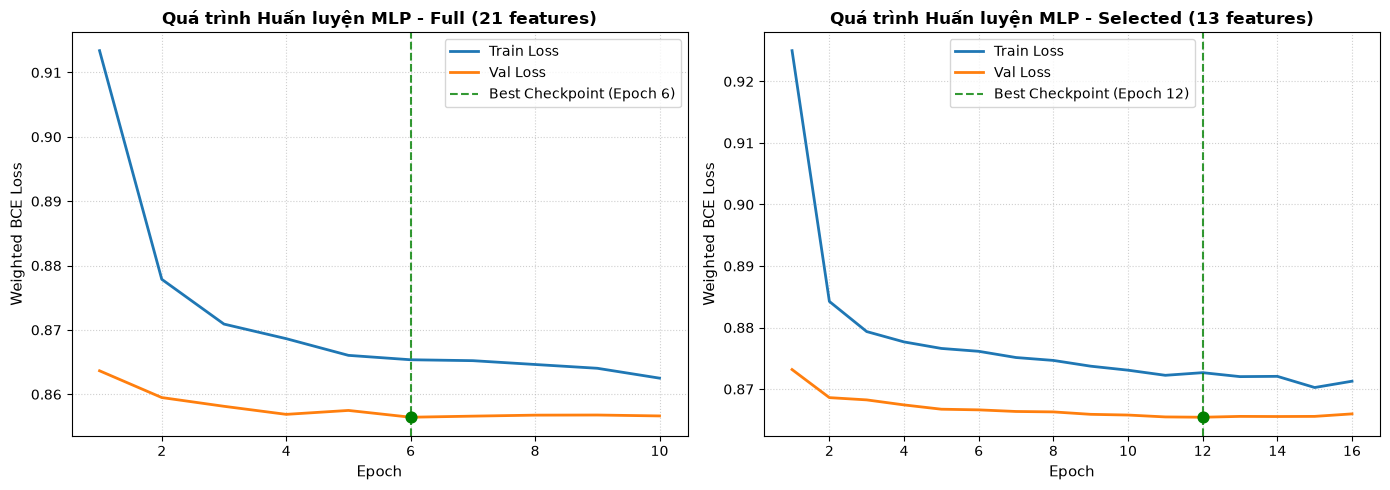

In [ ]:
results = []
histories = []
for ds_type, ds_label in [("full", "Full (21 features)"), ("selected", "Selected (13 features)")]:
    print(f"MLP -- {ds_label}")

    #dataloader prep
    train_loader, val_loader, test_loader, y_val, y_test, input_dim, pos_w = prepare_dataloaders(ds_type)
    print(f"Input dim = {input_dim} | pos_weight = {pos_w:.2f}")
    
    #trainning
    model, history, best_ep = train_mlp(train_loader, val_loader, input_dim, pos_w)
    histories.append((ds_label, history, best_ep))
    
    #Tìm ngưỡng tối ưu F2-Score trên tập VALIDATION (không đụng vào tập Test)
    y_prob_val = predict_proba_mlp(model, val_loader)
    best_thre, best_val_f2 = find_best_threshold(y_val, y_prob_val, beta=2.0)
    print(f"-> Ngưỡng tối ưu trên Val: Threshold = {best_thre} (Val F2 = {best_val_f2:.4f})")
    
    #Đánh giá trên tập TEST với ngưỡng vừa tìm được
    y_prob_test = predict_proba_mlp(model, test_loader)
    metrics_res = evaluate_model(
        y_true=y_test,
        y_prob=y_prob_test,
        threshold=best_thre,
        model_name="Baseline MLP",
        dataset_name=ds_label
    )
    results.append(metrics_res)
    
    # lưu kết quả
    np.save(f"../models/y_prob_mlp_{ds_type}.npy", y_prob_test)
    torch.save(model.state_dict(), f"../models/mlp_{ds_type}.pt")

df_results = pd.DataFrame(results)
display(df_results) 
plot_mlp_learning_curves(histories)